# 6r_no_offset: the 5r results without the national single-year offset

4r and 5r split each municipality's 5-year population bands into single years with the **national single-year Japanese population as offset** (人口推計, `dt/natpop_japanese_single_year.csv`). The offset puts the cohort-size cliffs that 5-year bands hide into the split: the small 1945–46 births next to the 1947–49 baby boom, and 1966 (丙午). It assumes that each municipality's within-band age shape follows the national one, up to a smooth ratio.

This notebook redoes 5r figures 1–7 with **no offset anywhere**. Population is split by plain `pclm` (1D, each count date separately) and plain `pclm2D` (2D, age × time). Only the municipality's own 5-year bands are used, with no outside information on the within-band shape.

**Unchanged from 5r**
- Smoothing: BIC for both λ, `kr` = 2, rescaling to keep every published band total.
- Deaths and movers: plain 1D pclm, as in 4r/5r (they never used the offset).
- Death timing, Lexis split, cohorts, groups, periods and the noise yardstick.

**Four population splits are compared** in figures 1–3:

| | with national offset | without (this notebook) |
|---|---|---|
| 1D `pclm` | 4r | new |
| 2D `pclm2D` | 5r | new |

Figures 4–7 are the 4r/5r group figures with the **2D split without offset**. 5r figure 8 already used plain `pclm2D` (the national shape ends in 2020), so it isn't repeated here.

Figures are written to `res/6r_<NN>_<item>.png`. Run 4r and 5r first: this notebook reads their caches for the offset variants and the deaths and movers.

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"

nb_prefix <- "6r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}
top_age <- 105

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Population: Basic Resident Register (住民基本台帳), Japanese residents. Deaths: Vital Statistics (人口動態統計), ",
                   "Japanese, by residence. Net migration = residual (population change + deaths).")

# One entry per disaster: population count years (labels as in the 住基 data),
# baseline count and the quake interval (identified by its starting count).
events <- list(
  tohoku   = list(title = "2011 Great East Japan Earthquake", groups = c("東日本", "福島"),
                  counts = 2006:2016, base = 2010, quake_start = 2010),
  kumamoto = list(title = "2016 Kumamoto Earthquake", groups = "熊本",
                  counts = 2011:2021, base = 2016, quake_start = 2016)
)

In [2]:
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 %in% c("東日本", "福島", "熊本")) |>
  transmute(event = ifelse(災害 == "熊本", "kumamoto", "tohoku"),
            code = 市町村コード, muni = 市町村, pref = 県, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`),
            evacuation = 避難指示あり %in% c("TRUE", "True", "1")) |>
  mutate(group = case_when(
    event == "tohoku" & pref == "福島県" & evacuation ~ "福島 避難指示 (evacuation order)",
    event == "tohoku" & pref != "福島県" & zenkai_rate >= 1 ~ "岩手・宮城 全壊率 ≥ 1",
    event == "tohoku" ~ "Other listed (Tohoku)",
    zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
    code == "43100" ~ "熊本市",
    TRUE ~ "Other listed (Kumamoto)"))
group_levels <- list(
  tohoku = c("岩手・宮城 全壊率 ≥ 1", "福島 避難指示 (evacuation order)", "Other listed (Tohoku)"),
  kumamoto = c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed (Kumamoto)"))
group_cols <- c(setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels$tohoku),
                setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels$kumamoto))

study |> count(event, group) |> as.data.frame()
study |> filter(event == "tohoku", zenkai_rate >= 1 | evacuation) |>
  arrange(group, desc(zenkai_rate)) |> select(group, pref, short, zenkai_rate) |>
  mutate(zenkai_rate = round(zenkai_rate, 2)) |> as.data.frame()

event,group,n
<chr>,<chr>,<int>
kumamoto,High damage (全壊率 ≥ 1),5
kumamoto,Other listed (Kumamoto),39
kumamoto,熊本市,1
tohoku,Other listed (Tohoku),91
tohoku,岩手・宮城 全壊率 ≥ 1,22
tohoku,福島 避難指示 (evacuation order),10


group,pref,short,zenkai_rate
<chr>,<chr>,<chr>,<dbl>
Other listed (Tohoku),福島県,新地町,5.20
Other listed (Tohoku),福島県,相馬市,2.63
Other listed (Tohoku),福島県,いわき市,2.27
Other listed (Tohoku),福島県,国見町,1.84
Other listed (Tohoku),福島県,矢吹町,1.62
Other listed (Tohoku),福島県,須賀川市,1.55
Other listed (Tohoku),福島県,鏡石町,1.32
Other listed (Tohoku),福島県,天栄村,1.11
岩手・宮城 全壊率 ≥ 1,宮城県,女川町,28.58


In [3]:
pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計") |>
  inner_join(study |> select(code, event), by = "code") |>
  filter(mapply(function(e, y) y %in% events[[e]]$counts, event, year)) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, event, year, ref_date, age_band, n = pop)

death_years <- list(tohoku = 2006:2015, kumamoto = 2011:2020)
dth5 <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, sex == "計") |>
  inner_join(study |> select(code, event), by = "code") |>
  filter(mapply(function(e, y) y %in% death_years[[e]], event, year)) |>
  mutate(age_band = as.character(age_band)) |>
  select(code, event, year, age_band, n)

# Coverage, and deaths of unknown age (dropped: they cannot be placed in a cohort)
bind_rows(pop5 |> filter(age_band == "total") |> mutate(series = "population"),
          dth5 |> filter(age_band == "total") |> mutate(series = "deaths")) |>
  group_by(event, series) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"),
            code_years = n(), total = sum(n), .groups = "drop") |>
  left_join(dth5 |> filter(age_band == "unknown") |> group_by(event) |>
              summarise(series = "deaths", unknown_age = sum(n)), by = c("event", "series")) |>
  as.data.frame()

event,series,municipalities,years,code_years,total,unknown_age
<chr>,<chr>,<int>,<chr>,<int>,<dbl>,<dbl>
kumamoto,deaths,45,2011–2020,450,209136,3
kumamoto,population,45,2011–2021,495,19712460,NA
tohoku,deaths,123,2006–2015,1230,538948,4
tohoku,population,123,2006–2016,1353,50948476,NA


In [4]:
band_table <- function(bands, counts) {
  keep <- !bands %in% c("total", "unknown")
  if (any(bands == "80_84")) keep <- keep & bands != "80+"
  tibble(band = bands[keep], n = counts[keep]) |>
    mutate(lower = as.integer(sub("[_+].*", "", band))) |>
    arrange(lower) |>
    mutate(upper = lead(lower, default = top_age))
}
# National Japanese population by single year (1 October, thousands), the
# within-band shape: src/build_natpop.R. 100+ is spread over 100-104.
nat <- readr::read_csv(file.path(root, "dt/natpop_japanese_single_year.csv"), show_col_types = FALSE)
N <- function(y) { v <- nat$pop[nat$year == y]; c(v[1:100], v[101] * c(0.4, 0.27, 0.17, 0.10, 0.06)) }
older <- function(v) c(v[1], v[-length(v)])          # shift by one year of age
# Shape at a count date: 31 March y is half a year after 1 October y-1, 1 January y a quarter
offset_count <- function(y, ref) { a <- N(y - 1); w <- if (ref == "01-01") 0.75 else 0.5; w * a + (1 - w) * older(a) }

# Plain pclm smooths away cohort-size cliffs that 5-year bands hide (the small
# 1945-46 births next to the 1947-49 boom, 1966). For population, pclm is run
# with the national single-year shape at the same date as offset: it then
# smooths the municipal/national ratio, so the cliffs come from the national
# shape. Every fit is rescaled within each band to keep the published band
# totals. If an offset fit misbehaves (non-positive values), the national
# within-band shares are used instead. Deaths use plain pclm.
ungroup_bands <- function(bands, counts, shape = NULL) {
  b <- band_table(bands, counts)
  ages <- 0:(top_age - 1)
  band <- findInterval(ages, b$lower)
  if (sum(b$n) == 0) return(tibble(age = ages, fit = 0, lo = 0, hi = 0, lambda = NA_real_, method = "zero"))
  m <- pclm(x = b$lower, y = pmax(b$n, 1e-4), nlast = top_age - max(b$lower),
            offset = shape, verbose = FALSE)
  k <- if (is.null(shape)) 1 else shape
  raw <- unname(fitted(m)) * k
  method <- if (is.null(shape)) "pclm" else "pclm + national offset"
  lo <- unname(m$ci$lower) * k; hi <- unname(m$ci$upper) * k
  if (!is.null(shape) && (any(!is.finite(raw)) || any(raw <= 0))) {
    raw <- shape; lo <- hi <- shape; method <- "national shares"
  }
  scale <- (b$n / pmax(tapply(raw, band, sum), 1e-12))[band]
  tibble(age = ages, fit = raw * scale, lo = lo * scale, hi = hi * scale,
         lambda = unname(m$smoothPar["lambda"]), method = method)
}

In [5]:
# 1D fits from 4r (population, deaths, Kumamoto movers)
cache1d <- file.path(root, "output/4r_pclm_cache.qs2")
if (!file.exists(cache1d)) stop("Run src/4r_residual_migration.ipynb first: it writes ", cache1d)
fits1d <- qs_read(cache1d)

# 2D population fits: one pclm2D per municipality over its event's count years.
# Bands are harmonised to ... 75-79, 80+ (80+ is the top band up to 2014).
to80 <- function(b) ifelse(b %in% c("80_84", "85_89", "90_94", "95_99", "100+"), "80+", b)
fit2d_muni <- function(g, use_offset = TRUE) {
  b <- g |> group_by(year) |>
    filter(age_band != "total", !(age_band == "80+" & any(age_band == "80_84"))) |>   # per year
    ungroup() |>
    mutate(band = to80(age_band)) |>
    group_by(year, ref, band) |> summarise(n = sum(n), .groups = "drop") |>
    mutate(lower = as.integer(sub("[_+].*", "", band)))
  Y <- b |> select(year, lower, n) |> pivot_wider(names_from = year, values_from = n) |> arrange(lower)
  yrs <- as.integer(colnames(Y)[-1])
  refs <- b |> distinct(year, ref) |> arrange(year)
  OFF <- if (use_offset) sapply(seq_along(yrs), function(i) offset_count(yrs[i], refs$ref[refs$year == yrs[i]])) else NULL
  m <- tryCatch(suppressWarnings(
    pclm2D(Y$lower, as.data.frame(Y[, -1]), nlast = top_age - max(Y$lower), offset = OFF, verbose = FALSE,
           control = list(lambda = c(NA, NA), kr = 2, int.lambda = c(0.1, 1e5)))),
    error = function(e) NULL)
  if (is.null(m)) return(NULL)
  raw <- as.matrix(fitted(m)) * (if (is.null(OFF)) 1 else OFF)
  if (any(!is.finite(raw)) || any(raw <= 0)) return(NULL)
  band <- findInterval(0:(top_age - 1), Y$lower)
  out <- lapply(seq_along(yrs), function(j) {
    sc <- (Y[[j + 1]] / tapply(raw[, j], band, sum))[band]
    tibble(year = yrs[j], age = 0:(top_age - 1), fit = raw[, j] * sc)
  })
  bind_rows(out) |> mutate(lambda_age = m$smoothPar[["lambda.x"]], lambda_time = m$smoothPar[["lambda.y"]])
}


# Offset variants, from the 4r and 5r caches
cache2d <- file.path(root, "output/5r_pclm2d_cache.qs2")
if (!file.exists(cache2d)) stop("Run src/5r_ungroup2d.ipynb first: it writes ", cache2d)
fits2d_off <- qs_read(cache2d)

# No-offset variants: plain pclm per count date (1D) and plain pclm2D per
# municipality (2D). The 2D fits take 4 s - 2 min each, so they run in parallel.
cache_plain <- file.path(root, "output/6r_pclm_plain_cache.qs2")
if (file.exists(cache_plain)) {
  plain <- qs_read(cache_plain)
} else {
  t0 <- Sys.time()
  inp <- pop5 |> mutate(ref = substr(ref_date, 6, 10))
  p1 <- inp |> group_by(code, year) |>
    group_modify(function(g, k) ungroup_bands(g$age_band, g$n)) |> ungroup()
  codes <- unique(inp$code)
  p2 <- parallel::mclapply(codes, function(cd) {
    r <- fit2d_muni(inp |> filter(code == cd), use_offset = FALSE)
    if (is.null(r)) NULL else mutate(r, code = cd, .before = 1)
  }, mc.cores = max(1, parallel::detectCores() - 2), mc.preschedule = FALSE)
  plain <- list(pop1d = p1, pop2d = bind_rows(p2))
  message("Plain fits: ", n_distinct(p1$code), " (1D), ", n_distinct(plain$pop2d$code), " (2D) municipalities in ",
          round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(plain, cache_plain)
}
# Municipalities whose 2D fit failed fall back to the 1D fit of the same kind (listed here)
failed_off <- setdiff(study$code, fits2d_off$code)
failed_plain <- setdiff(study$code, plain$pop2d$code)
study |> filter(code %in% union(failed_off, failed_plain)) |>
  mutate(failed_with_offset = code %in% failed_off, failed_without = code %in% failed_plain) |>
  select(event, short, failed_with_offset, failed_without) |> as.data.frame()

# Smoothing chosen by BIC
bind_rows(fits2d_off |> mutate(variant = "2D with offset (5r)"), plain$pop2d |> mutate(variant = "2D without offset")) |>
  distinct(variant, code, lambda_age, lambda_time) |>
  group_by(variant) |>
  summarise(municipalities = n(), lambda_age_median = signif(median(lambda_age), 3),
            lambda_time_median = signif(median(lambda_time), 3),
            at_upper_limit = sum(lambda_age >= 1e5 * 0.999 | lambda_time >= 1e5 * 0.999), .groups = "drop") |>
  as.data.frame()

Plain fits: 168 (1D), 168 (2D) municipalities in 97.4 min



event,short,failed_with_offset,failed_without
<chr>,<chr>,<lgl>,<lgl>


variant,municipalities,lambda_age_median,lambda_time_median,at_upper_limit
<chr>,<int>,<dbl>,<dbl>,<int>
2D with offset (5r),168,23600,100000,149
2D without offset,168,1040,86700,76


## Residuals with the four population splits

Deaths, death timing and the residual formula are as in 4r and 5r. Only the population fits differ.

In [6]:
D <- fits1d |> filter(series == "deaths") |> select(code, year, age, D = fit)
Dw <- D |> pivot_wider(names_from = year, values_from = D, names_prefix = "D")
dget <- function(y) Dw[[paste0("D", y)]]

# Deaths per interval, keyed by the interval's starting count year
interval_deaths <- function(start) {
  if (start <= 2011) {
    d <- 0.75 * dget(start) + 0.25 * dget(start + 1)
  } else if (start == 2012) {
    d <- 0.75 * dget(2012)
  } else {
    d <- dget(start)
  }
  tibble(code = Dw$code, age = Dw$age, start = start, Dint = d)
}
tohoku_codes <- study$code[study$event == "tohoku"]
# Interval that receives the 2011 excess deaths: 2011 = 2011-03-31 -> 2012-03-31,
# when the register removed the victims (see the text above and the check below)
if (!exists("excess_to")) excess_to <- 2011
# Tohoku 2011: usual level B and excess E
B <- 0.5 * (dget(2009) + dget(2010))
E <- dget(2011) - B
starts <- 2006:2020   # interval starting counts used by either event
DI <- bind_rows(lapply(starts, function(s) {
  if (s %in% 2010:2011) {
    d <- interval_deaths(s)
    tt <- d$code %in% tohoku_codes & !is.na(B)
    if (s == 2010) d$Dint[tt] <- (0.75 * dget(2010) + 0.25 * B + (excess_to == 2010) * E)[tt]
    if (s == 2011) d$Dint[tt] <- (0.75 * B + 0.25 * dget(2012) + (excess_to == 2011) * E)[tt]
    d
  } else interval_deaths(s)
})) |> filter(!is.na(Dint))

In [7]:
span_of <- function(s) ifelse(s == 2012, 0.75, 1)
periods <- c("Before", "Quake interval", "After, years 1–2", "After, later")
period_cols <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b"), periods)
bands5 <- paste0(seq(0, 80, 5), "–", seq(4, 84, 5))
cohort_bins <- c(paste0(seq(0, 35, 5), "–", seq(4, 39, 5)), "40–49", "50–59", "60–69", "70–84")
cohort_of <- function(a0) {
  lab <- case_when(a0 < 40 ~ paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                   a0 < 70 ~ paste0(a0 %/% 10 * 10, "–", a0 %/% 10 * 10 + 9),
                   a0 <= 84 ~ "70–84", TRUE ~ NA_character_)
  factor(lab, levels = cohort_bins)
}

# Residual per single-year cohort for a given set of population fits P
compute_res <- function(P) {
  res1 <- P |>
    rename(start = count, P0 = P) |>
    inner_join(P |> transmute(code, start = count - 1, age = age - 1, P1_next = P), by = c("code", "start", "age")) |>
    left_join(P |> transmute(code, start = count - 1, age, P1_same = P), by = c("code", "start", "age")) |>
    inner_join(DI |> group_by(code, start) |> arrange(age, .by_group = TRUE) |>
                 mutate(Dc = 0.5 * (Dint + lead(Dint, default = 0))) |> ungroup() |>
                 select(code, start, age, Dc), by = c("code", "start", "age")) |>
    inner_join(study |> select(code, event, short, group), by = "code") |>
    filter(mapply(function(e, s) s %in% head(events[[e]]$counts, -1), event, start)) |>
    mutate(span = span_of(start),
           P1 = ifelse(start == 2012, 0.75 * P1_next + 0.25 * coalesce(P1_same, P1_next), P1_next),
           NM = P1 - P0 + Dc)
  
  
  res1 |>
    mutate(q = mapply(function(e) events[[e]]$quake_start, event),
           period = factor(case_when(start < q ~ periods[1], start == q ~ periods[2],
                                     start <= q + 2 ~ periods[3], TRUE ~ periods[4]), levels = periods),
           band = factor(ifelse(age <= 84, paste0(age %/% 5 * 5, "–", age %/% 5 * 5 + 4), NA), levels = bands5),
           base = mapply(function(e) events[[e]]$base, event),
           a0 = age - (start - base),
           cohort = cohort_of(a0))
}

variants <- c("1D with offset (4r)", "2D with offset (5r)", "1D without offset", "2D without offset")
P_1o <- fits1d |> filter(series == "pop") |> select(code, count = year, age, P = fit)
P_1p <- plain$pop1d |> select(code, count = year, age, P = fit)
P_2o <- bind_rows(fits2d_off |> select(code, count = year, age, P = fit), P_1o |> filter(code %in% failed_off))
P_2p <- bind_rows(plain$pop2d |> select(code, count = year, age, P = fit), P_1p |> filter(code %in% failed_plain))
Ps <- setNames(list(P_1o, P_2o, P_1p, P_2p), variants)
res_all <- lapply(Ps, compute_res)
res_2p <- res_all[["2D without offset"]]

# Accounting check (as in 4r): residual + newborns + half infant deaths = population change + deaths
acc <- function(res, P, label) {
  res |> group_by(event, code, start) |> summarise(NM = sum(NM), .groups = "drop") |>
    left_join(P |> group_by(code, count) |> summarise(Ptot = sum(P), .groups = "drop") |>
                transmute(code, start = count, Pstart = Ptot), by = c("code", "start")) |>
    left_join(P |> group_by(code, count) |> summarise(Ptot = sum(P), P0 = sum(P[age == 0]), .groups = "drop") |>
                transmute(code, start = count - 1, Pend = Ptot, Pend0 = P0), by = c("code", "start")) |>
    left_join(DI |> group_by(code, start) |> summarise(Dtot = sum(Dint), D0 = sum(Dint[age == 0]), .groups = "drop"),
              by = c("code", "start")) |>
    group_by(event) |>
    summarise(method = label, residual = round(sum(NM)),
              unexplained = round(sum(Pend - Pstart + Dtot) - sum(NM) -
                                  sum(ifelse(start == 2012, 0.75, 1) * Pend0 + 0.5 * D0)), .groups = "drop")
}
bind_rows(Map(acc, res_all, Ps, variants)) |> arrange(event, match(method, variants)) |> as.data.frame()

# Shared styling for the four variants: colour = 1D/2D, line type = offset or not
var_col <- setNames(c("#8a8a85", "#2a78d6", "#8a8a85", "#2a78d6"), variants)
var_lty <- setNames(c("solid", "solid", "22", "22"), variants)

event,method,residual,unexplained
<chr>,<chr>,<dbl>,<dbl>
kumamoto,1D with offset (4r),-29302,-487
kumamoto,2D with offset (5r),-28744,-930
kumamoto,1D without offset,-29104,-603
kumamoto,2D without offset,-27916,-482
tohoku,1D with offset (4r),-149436,-1194
tohoku,2D with offset (5r),-149963,-1762
tohoku,1D without offset,-144452,-2091
tohoku,2D without offset,-143067,-1560


## Figure 1: single-age residuals in the pre-quake years, with and without the offset

Pooled "Other listed" municipalities, pre-quake full-year intervals, single ages 40–85 at the interval start, as in 5r figure 1. Real migration at these ages is small and changes slowly, so zig-zags are method noise. Without the offset, the hidden cliff between the 1945–46 and 1947–49 births can only show up as a wave over the neighbouring ages.

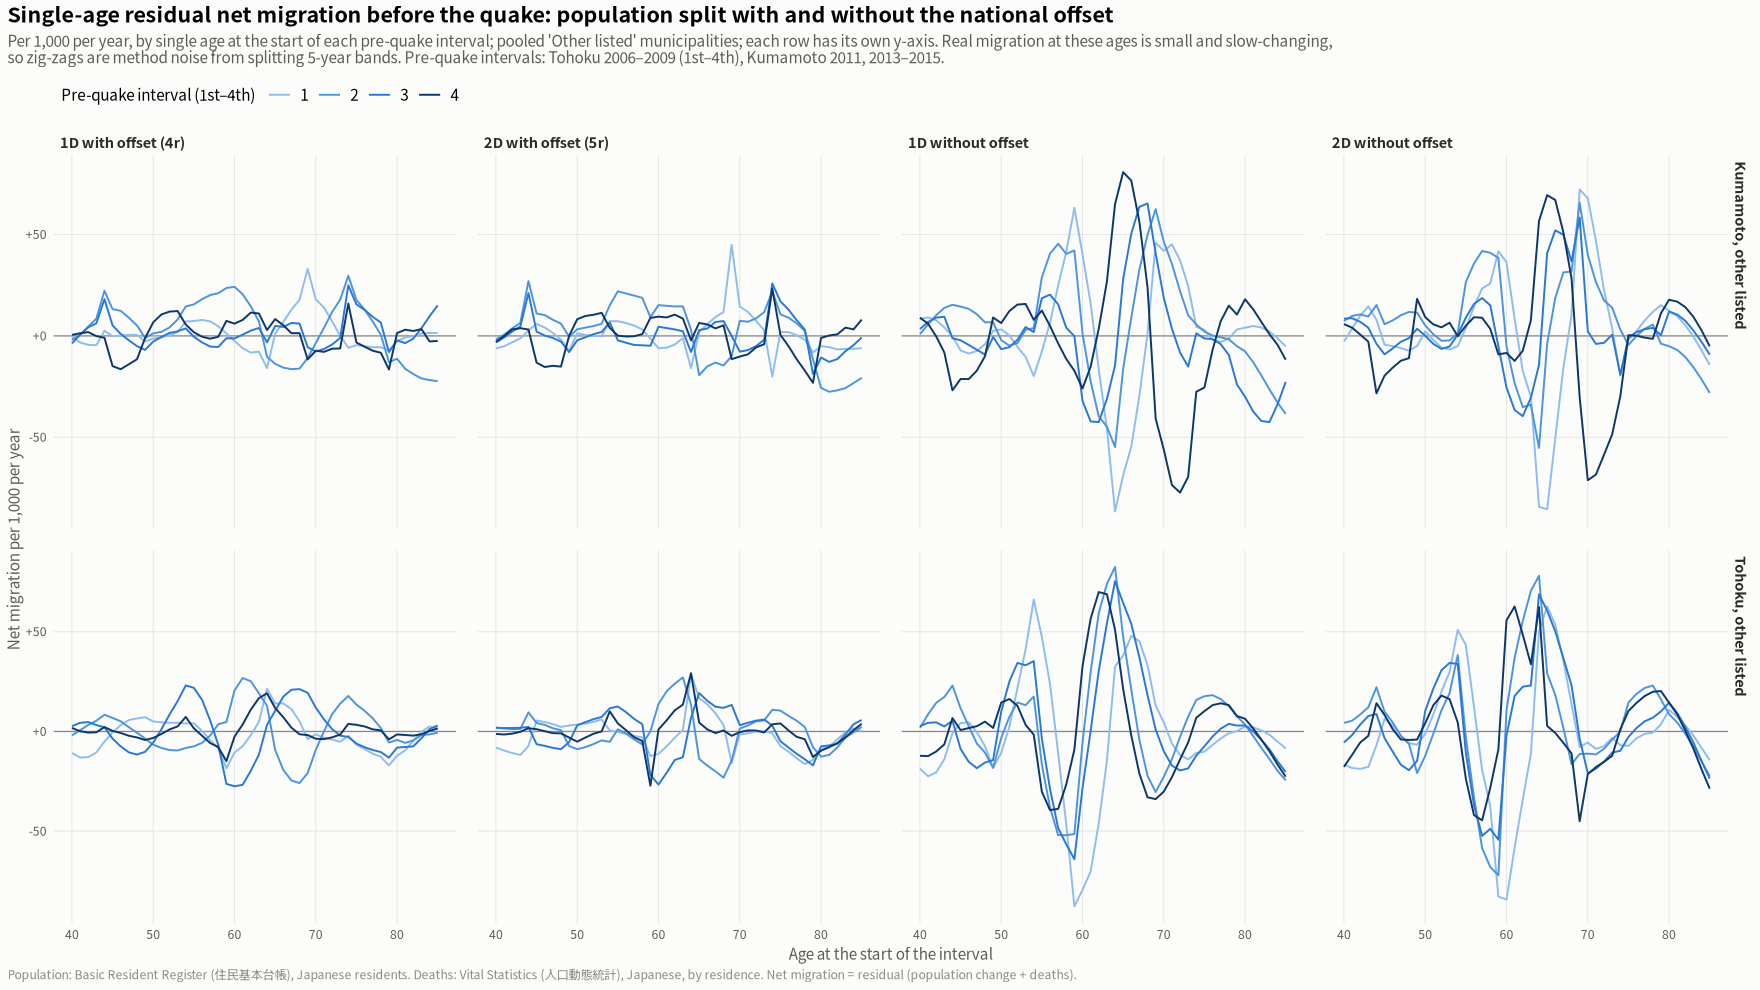

In [8]:
sa <- bind_rows(Map(function(r, v) mutate(r, method = v), res_all, variants)) |>
  filter(grepl("^Other", group), start < q, span == 1, age %in% 40:85) |>
  group_by(method, event, start, age) |>
  summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop") |>
  mutate(method = factor(method, levels = variants),
         event = factor(ifelse(event == "tohoku", "Tohoku, other listed", "Kumamoto, other listed"))) |>
  group_by(event) |> mutate(k = factor(dense_rank(start))) |> ungroup()
p1 <- ggplot(sa, aes(age, rate, colour = k, group = k)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_line(linewidth = 0.6) +
  facet_grid(event ~ method, scales = "free_y") +
  scale_colour_manual(values = c("#8fbcef", "#4d94e0", "#2a78d6", "#0d366b"),
                      name = "Pre-quake interval (1st–4th)") +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "Single-age residual net migration before the quake: population split with and without the national offset",
       subtitle = paste0("Per 1,000 per year, by single age at the start of each pre-quake interval; pooled 'Other listed' municipalities; each row has its own y-axis. ",
                         "Real migration at these ages is small and slow-changing,\nso zig-zags are method noise from splitting 5-year bands. ",
                         "Pre-quake intervals: Tohoku 2006–2009 (1st–4th), Kumamoto 2011, 2013–2015."),
       x = "Age at the start of the interval", y = "Net migration per 1,000 per year", caption = src_note) +
  base_theme() + theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3))
show_save(p1, "01_single_age_residual_offset_vs_none", width = 18, height = 8)

## Figure 2: method noise by age band, with and without the offset

As in 5r figure 2: for each group and 5-year age band, the SD across the single pre-quake (full-year) intervals of the net rate. Lower is better.

event,group,method,all_ages,ages_0_14,ages_20_39,ages_55_79
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
kumamoto,High damage (全壊率 ≥ 1),1D with offset (4r),13.3,6.3,10.9,15.2
kumamoto,High damage (全壊率 ≥ 1),2D with offset (5r),11.9,6.0,10.5,12.1
kumamoto,High damage (全壊率 ≥ 1),1D without offset,13.5,6.5,11.2,27.2
kumamoto,High damage (全壊率 ≥ 1),2D without offset,12.3,5.8,11.3,20.2
kumamoto,Other listed (Kumamoto),1D with offset (4r),7.7,3.6,8.2,8.2
kumamoto,Other listed (Kumamoto),2D with offset (5r),7.4,3.1,7.5,7.9
kumamoto,Other listed (Kumamoto),1D without offset,9.4,5.2,8.8,20.6
kumamoto,Other listed (Kumamoto),2D without offset,7.7,4.8,8.5,17.7
kumamoto,熊本市,1D with offset (4r),7.5,5.0,6.0,6.3


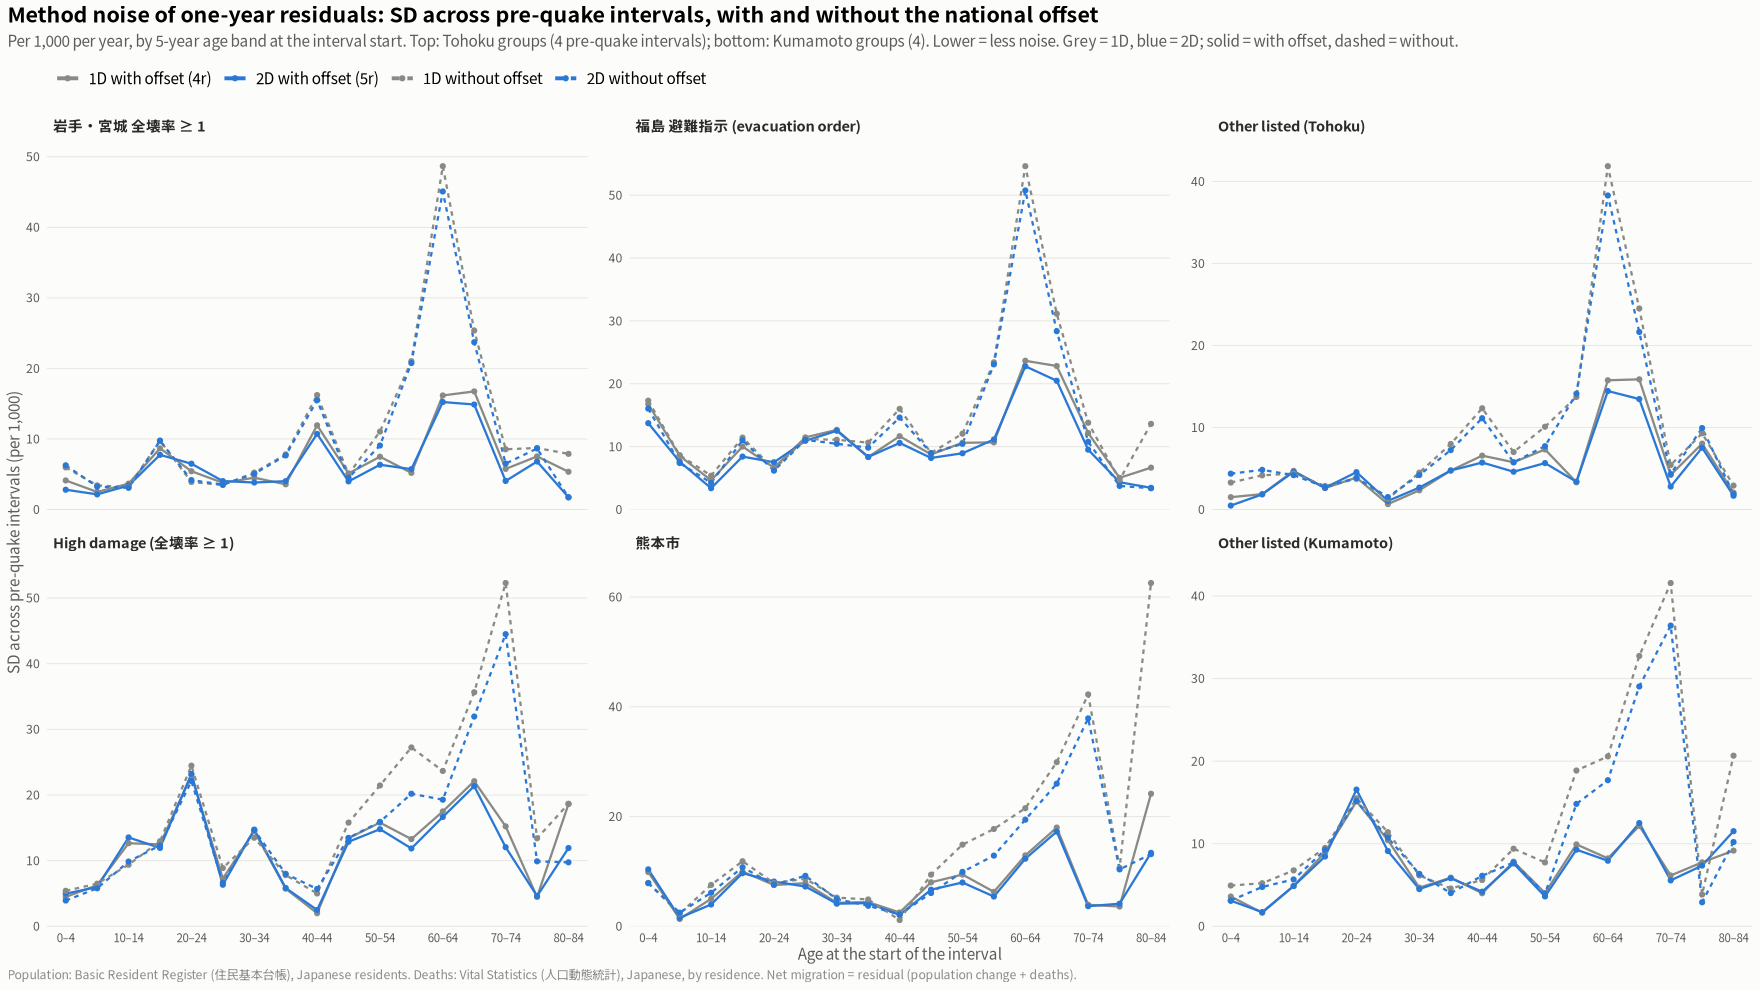

In [9]:
noise_of <- function(res, label) {
  res |> filter(!is.na(band), start < q, span == 1) |>
    group_by(event, group, band, start) |>
    summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop") |>
    group_by(event, group, band) |>
    summarise(pre_mean = mean(rate), pre_sd = sd(rate), .groups = "drop") |>
    mutate(method = label)
}
nz <- bind_rows(Map(noise_of, res_all, variants)) |> mutate(method = factor(method, levels = variants))

# Table: median noise SD over age bands, by group (and for the target ages)
nz |> group_by(event, group, method) |>
  summarise(all_ages = round(median(pre_sd), 1),
            ages_0_14 = round(median(pre_sd[band %in% bands5[1:3]]), 1),
            ages_20_39 = round(median(pre_sd[band %in% bands5[5:8]]), 1),
            ages_55_79 = round(median(pre_sd[band %in% bands5[12:16]]), 1), .groups = "drop") |>
  as.data.frame()

p2 <- ggplot(nz |> mutate(group = factor(group, levels = unlist(group_levels))),
             aes(band, pre_sd, colour = method, linetype = method, group = method)) +
  geom_line(linewidth = 0.7) + geom_point(size = 1.3) +
  facet_wrap(~group, nrow = 2, scales = "free_y") +
  scale_colour_manual(values = var_col, name = NULL) +
  scale_linetype_manual(values = var_lty, name = NULL) +
  scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, b, "")) +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
  labs(title = "Method noise of one-year residuals: SD across pre-quake intervals, with and without the national offset",
       subtitle = paste0("Per 1,000 per year, by 5-year age band at the interval start. Top: Tohoku groups (4 pre-quake intervals); bottom: Kumamoto groups (4). ",
                         "Lower = less noise. Grey = 1D, blue = 2D; solid = with offset, dashed = without."),
       x = "Age at the start of the interval", y = "SD across pre-quake intervals (per 1,000)", caption = src_note) +
  base_theme() + theme(axis.text.x = element_text(size = 7.5)) +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.2)))
show_save(p2, "02_noise_offset_vs_none", width = 16, height = 9)

## Figure 3: validation against reported migration, with and without the offset (Kumamoto 2014–2020)

As in 5r figure 3. The reported side (in − out Japanese movers, 1D split) is the same for all four variants; only the population split differs.

In [10]:
M1 <- fits1d |> filter(series %in% c("in", "out")) |>
  select(code, year, series, age, M = fit) |>
  group_by(code, year, series) |> arrange(age, .by_group = TRUE) |>
  mutate(Mc = 0.5 * (M + lead(M, default = 0))) |> ungroup() |>
  select(-M) |> pivot_wider(names_from = series, values_from = Mc)

In [11]:
val_of <- function(res, label) {
  res |> filter(event == "kumamoto", start %in% 2014:2020, !is.na(cohort)) |>
    inner_join(M1 |> rename(start = year), by = c("code", "start", "age")) |>
    group_by(code, short, group, cohort, start) |>
    summarise(P0 = sum(P0), NM = sum(NM), rep = sum(`in`) - sum(out), .groups = "drop") |>
    mutate(residual = 1000 * NM / P0, reported = 1000 * rep / P0, gap = residual - reported, method = label)
}
val <- bind_rows(Map(val_of, res_all, variants)) |> mutate(method = factor(method, levels = variants))
munipop <- pop5 |> filter(age_band == "total", year == 2016) |> select(code, pop2016 = n)
val <- val |> left_join(munipop, by = "code") |>
  mutate(size = cut(pop2016, c(0, 5000, 10000, 20000, 50000, 1e7),
                    labels = c("< 5k", "5–10k", "10–20k", "20–50k", "≥ 50k")))

cat("By cohort bin:\n")
val |> group_by(cohort, method) |>
  summarise(sd_gap = round(sd(gap), 1), corr = round(cor(residual, reported), 2), .groups = "drop") |>
  pivot_wider(names_from = method, values_from = c(sd_gap, corr)) |> as.data.frame()
cat("By municipality size:\n")
val |> group_by(size, method) |>
  summarise(sd_gap = round(sd(gap), 1), corr = round(cor(residual, reported), 2), .groups = "drop") |>
  pivot_wider(names_from = method, values_from = c(sd_gap, corr)) |> as.data.frame()
cat("Whole municipality-years (all cohorts summed) and all cells:\n")
val |> group_by(method) |>
  summarise(cells_corr = round(cor(residual, reported), 3), cells_sd_gap = round(sd(gap), 1), .groups = "drop") |>
  left_join(val |> group_by(method, code, start) |>
              summarise(r = 1000 * sum(NM) / sum(P0), p = 1000 * sum(rep) / sum(P0), .groups = "drop") |>
              group_by(method) |> summarise(muni_corr = round(cor(r, p), 3), muni_sd_gap = round(sd(r - p), 2)),
            by = "method") |> as.data.frame()

By cohort bin:


cohort,sd_gap_1D with offset (4r),sd_gap_2D with offset (5r),sd_gap_1D without offset,sd_gap_2D without offset,corr_1D with offset (4r),corr_2D with offset (5r),corr_1D without offset,corr_2D without offset
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,40.1,37.7,40.1,37.1,0.35,0.38,0.35,0.40
5–9,24.9,23.1,25.2,23.1,0.53,0.55,0.52,0.53
10–14,33.5,30.7,33.9,30.8,0.45,0.50,0.46,0.52
15–19,36.8,34.4,36.8,34.3,0.75,0.78,0.75,0.77
20–24,39.7,38.5,40.0,39.1,0.72,0.72,0.71,0.72
25–29,32.6,31.2,33.6,31.9,0.67,0.68,0.66,0.67
30–34,28.7,27.4,29.5,27.7,0.60,0.61,0.59,0.60
35–39,28.1,26.2,28.0,25.7,0.50,0.52,0.51,0.52
40–49,14.6,13.4,15.5,14.1,0.58,0.60,0.55,0.57


By municipality size:


size,sd_gap_1D with offset (4r),sd_gap_2D with offset (5r),sd_gap_1D without offset,sd_gap_2D without offset,corr_1D with offset (4r),corr_2D with offset (5r),corr_1D without offset,corr_2D without offset
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
< 5k,50.8,48.7,51.2,48.7,0.60,0.62,0.60,0.62
5–10k,27.7,26.4,28.9,26.9,0.72,0.74,0.71,0.73
10–20k,21.4,19.4,23.4,20.6,0.81,0.83,0.78,0.82
20–50k,12.5,11.1,14.7,12.8,0.87,0.89,0.83,0.87
≥ 50k,8.5,7.7,11.5,10.4,0.92,0.93,0.86,0.88


Whole municipality-years (all cohorts summed) and all cells:


method,cells_corr,cells_sd_gap,muni_corr,muni_sd_gap
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
1D with offset (4r),0.717,28.2,0.973,1.72
2D with offset (5r),0.734,26.6,0.967,1.97
1D without offset,0.704,29.3,0.970,1.83
2D without offset,0.730,27.3,0.972,1.75


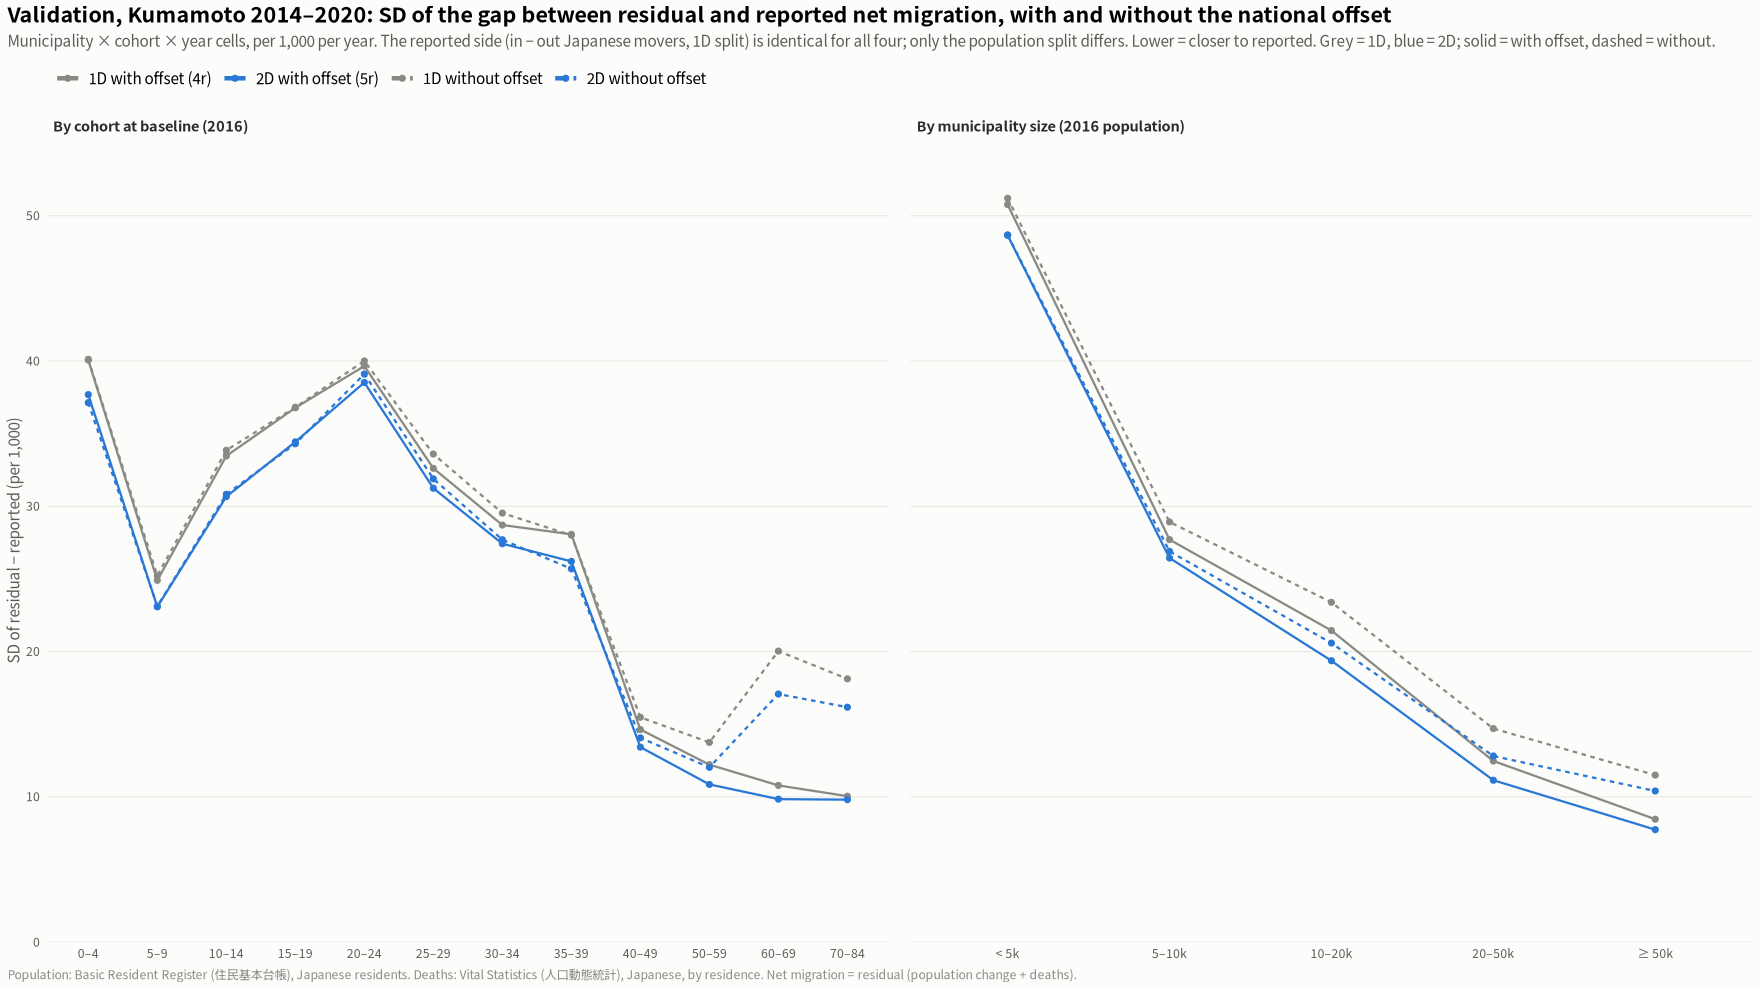

In [12]:
vs <- bind_rows(
  val |> group_by(method, x = cohort) |> summarise(sd_gap = sd(gap), .groups = "drop") |> mutate(panel = "By cohort at baseline (2016)"),
  val |> group_by(method, x = size) |> summarise(sd_gap = sd(gap), .groups = "drop") |> mutate(panel = "By municipality size (2016 population)")) |>
  mutate(x = factor(x, levels = c(cohort_bins, "< 5k", "5–10k", "10–20k", "20–50k", "≥ 50k")))
p3 <- ggplot(vs, aes(x, sd_gap, colour = method, linetype = method, group = method)) +
  geom_line(linewidth = 0.7) + geom_point(size = 1.6) +
  facet_wrap(~panel, scales = "free_x") +
  scale_colour_manual(values = var_col, name = NULL) +
  scale_linetype_manual(values = var_lty, name = NULL) +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
  labs(title = "Validation, Kumamoto 2014–2020: SD of the gap between residual and reported net migration, with and without the national offset",
       subtitle = paste0("Municipality × cohort × year cells, per 1,000 per year. The reported side (in − out Japanese movers, 1D split) is identical for all four; ",
                         "only the population split differs. Lower = closer to reported. Grey = 1D, blue = 2D; solid = with offset, dashed = without."),
       x = NULL, y = "SD of residual − reported (per 1,000)", caption = src_note) +
  base_theme() +
  guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
show_save(p3, "03_validation_offset_vs_none", width = 16, height = 6.5)

## Figures 4–7: the 4r group figures with the 2D split without offset

The same figures as 4r figures 2–5 and 5r figures 4–7, recomputed with plain `pclm2D` population splits. Noise bands and ⚠ flags are drawn as before, from these residuals. Compare with `res/5r_04` … `5r_07` (2D with offset).

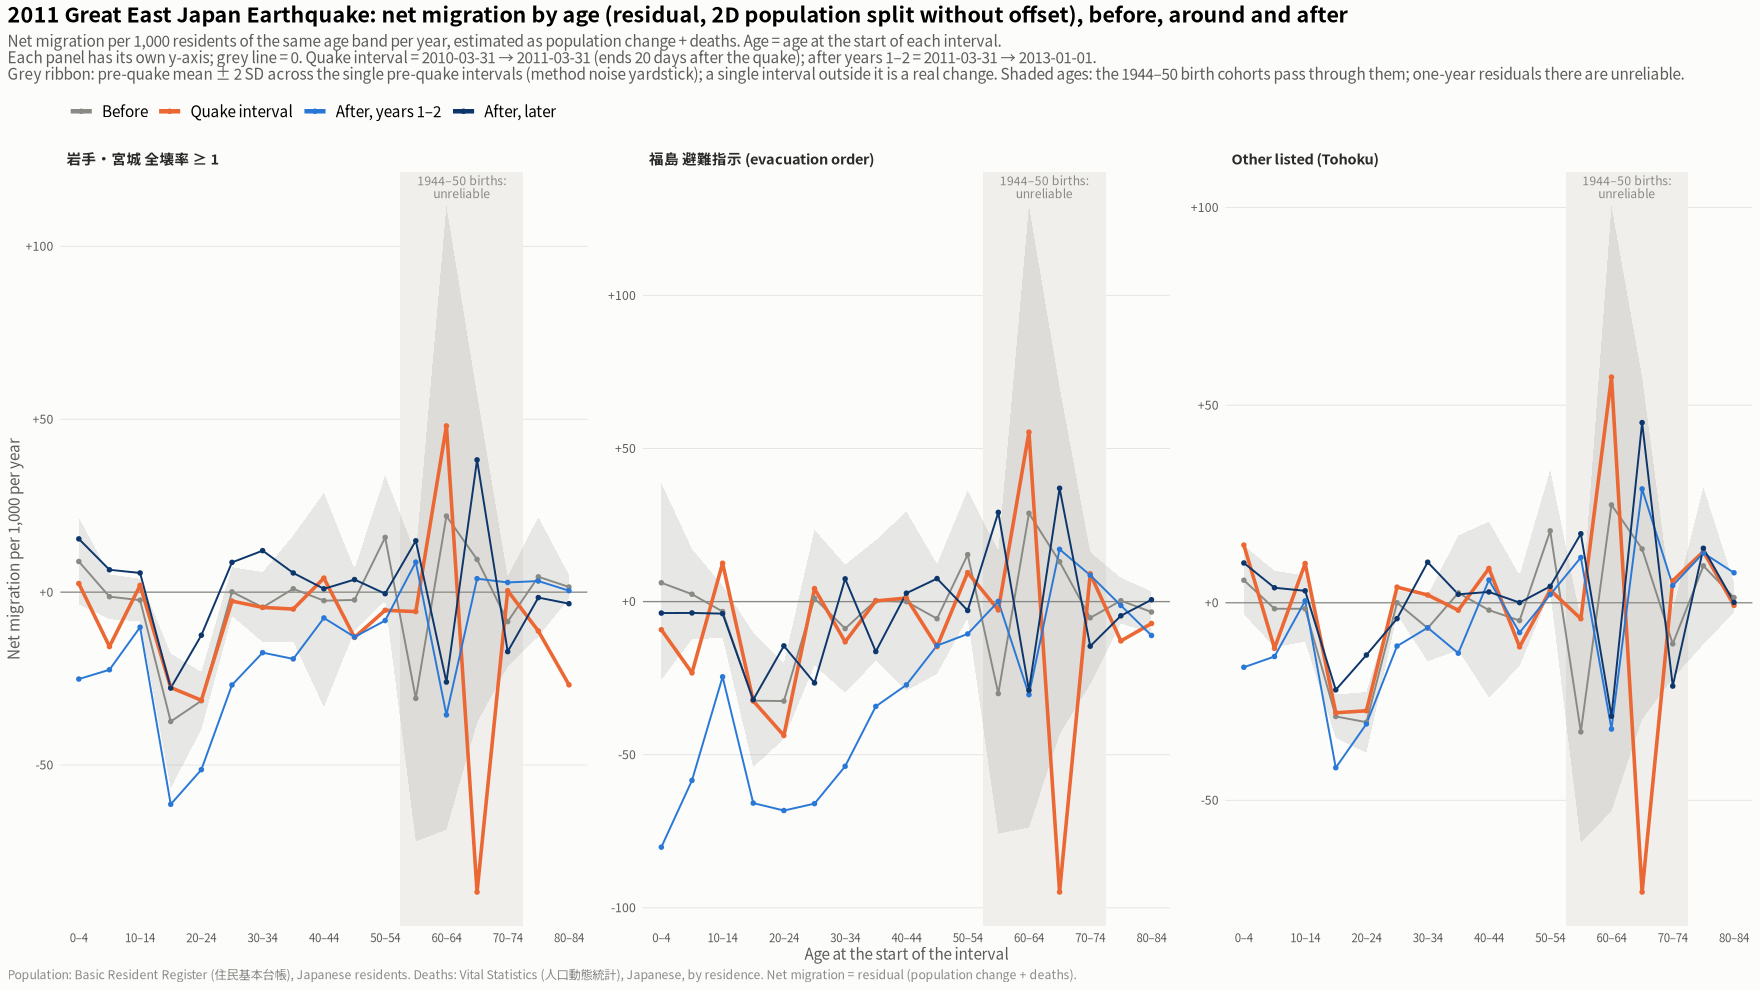

In [13]:
res1 <- res_2p |> filter(a0 >= 0)
profile <- res1 |> filter(!is.na(band)) |>
  group_by(event, group, period, band) |>
  summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")
noise <- noise_of(res_2p, "2D without offset")
cliff_births <- 1944:1950
cliff_bands <- lapply(events, function(ev) {
  st <- head(ev$counts, -1)
  ages <- range(outer(st, cliff_births, function(t, b) t - b - 1))
  bands5[seq(ages[1] %/% 5 + 1, min(ages[2] %/% 5 + 1, length(bands5)))]
})


plot_profile <- function(e) {
  dd <- profile |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  nz <- noise |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  cb <- match(cliff_bands[[e]], bands5)
  ggplot(dd, aes(band, rate, colour = period, group = period)) +
    annotate("rect", xmin = min(cb) - 0.5, xmax = max(cb) + 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("text", x = mean(cb), y = Inf, label = "1944–50 births:\nunreliable", vjust = 1.2,
             size = 2.8, colour = ink3, family = jp_font, lineheight = 0.9) +
    geom_ribbon(data = nz, aes(x = band, ymin = pre_mean - 2 * pre_sd, ymax = pre_mean + 2 * pre_sd, group = 1),
                inherit.aes = FALSE, fill = "#8a8a85", alpha = 0.18) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(aes(linewidth = period == periods[2])) +
    geom_point(size = 1.1) +
    facet_wrap(~group, nrow = 1, scales = "free_y") +
    scale_colour_manual(values = period_cols, name = NULL) +
    scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
    scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, b, "")) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(events[[e]]$title, ": net migration by age (residual), before, around and after"),
         subtitle = paste0("Net migration per 1,000 residents of the same age band per year, estimated as population change + deaths. ",
                           "Age = age at the start of each interval.\nEach panel has its own y-axis; grey line = 0. ",
                           if (e == "tohoku") "Quake interval = 2010-03-31 → 2011-03-31 (ends 20 days after the quake); after years 1–2 = 2011-03-31 → 2013-01-01."
                           else "Quake interval = calendar 2016; after years 1–2 = 2017–2018; later = 2019–2020.",
                           "\nGrey ribbon: pre-quake mean ± 2 SD across the single pre-quake intervals (method noise yardstick); a single interval outside it is a real change. ",
                           "Shaded ages: the 1944–50 birth cohorts pass through them; one-year residuals there are unreliable."),
         x = "Age at the start of the interval", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme() +
    theme(axis.text.x = element_text(size = 7.5)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}

show_save(plot_profile("tohoku") + labs(title = "2011 Great East Japan Earthquake: net migration by age (residual, 2D population split without offset), before, around and after"),
          "04_tohoku_age_profile_2d_no_offset", width = 16, height = 6.5)

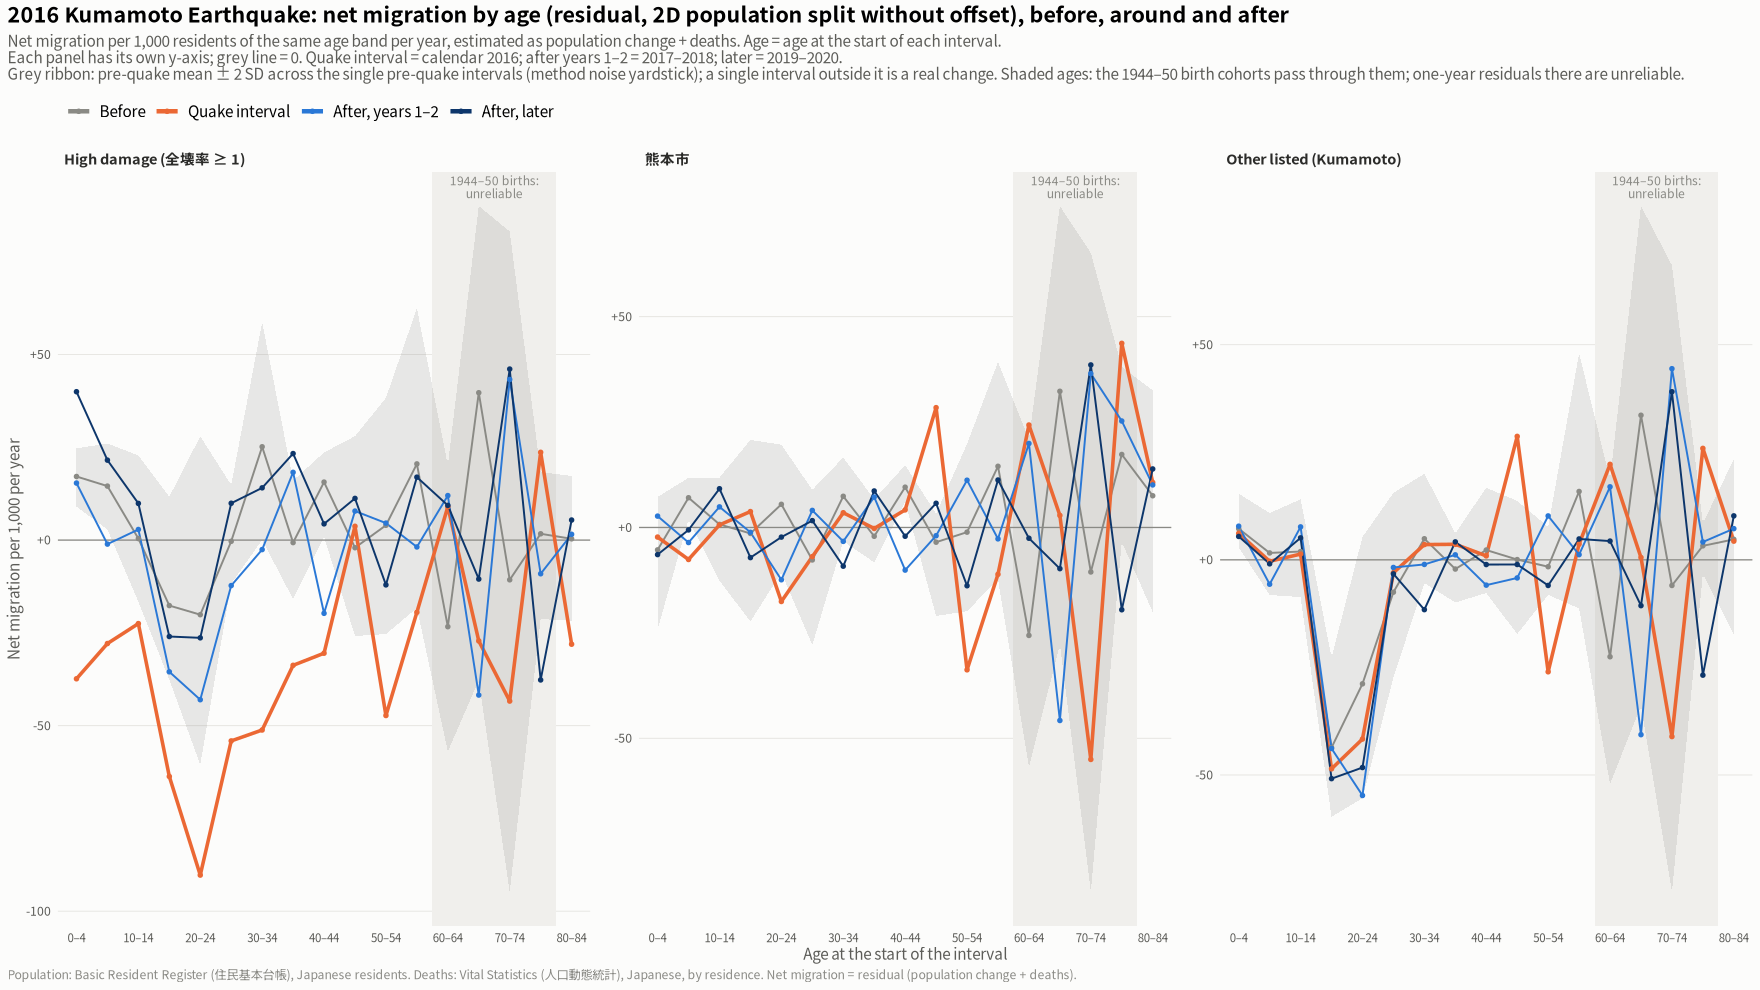

In [14]:
show_save(plot_profile("kumamoto") + labs(title = "2016 Kumamoto Earthquake: net migration by age (residual, 2D population split without offset), before, around and after"),
          "05_kumamoto_age_profile_2d_no_offset", width = 16, height = 6.5)

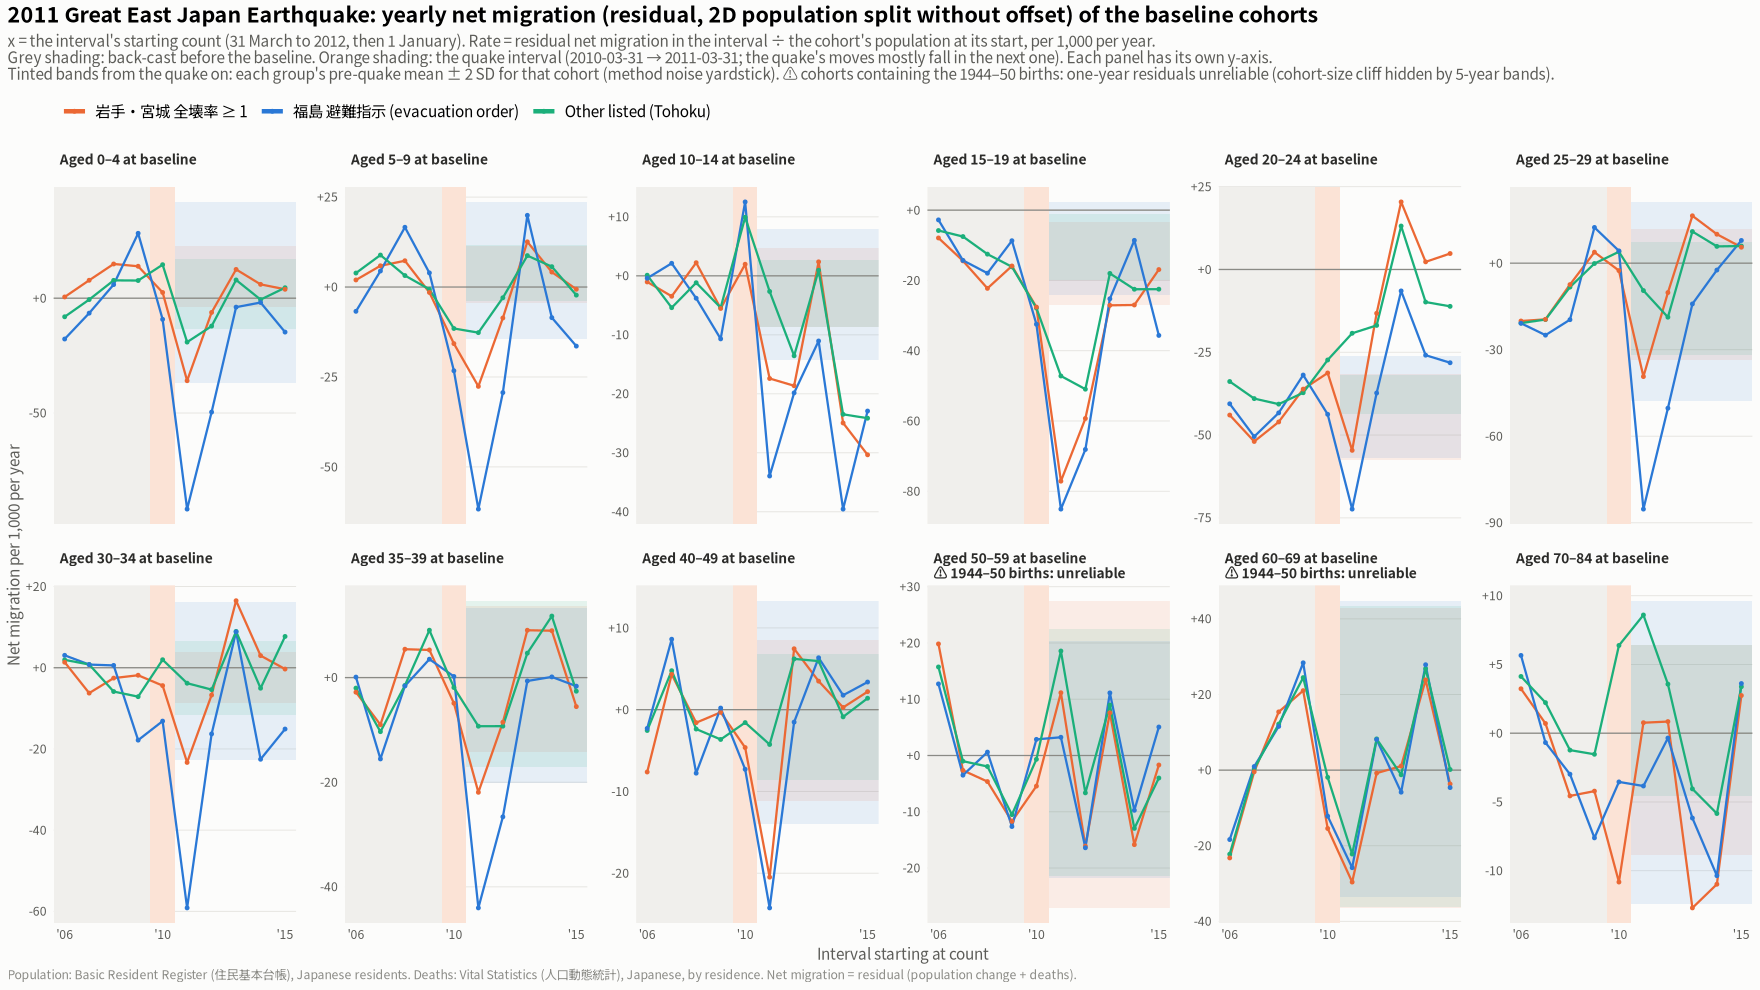

In [15]:
cr_group <- res1 |> filter(!is.na(cohort)) |>
  group_by(event, group, cohort, start) |>
  summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")
plot_cohorts <- function(e) {
  ev <- events[[e]]
  # cohort bins containing the 1944-50 births are flagged in the panel title
  born <- function(lab) { r <- as.integer(strsplit(as.character(lab), "–")[[1]]); ev$base - rev(r) - 1 }
  flag <- sapply(cohort_bins, function(b) any(born(b)[1]:born(b)[2] %in% cliff_births))
  labs_c <- paste0("Aged ", cohort_bins, " at baseline", ifelse(flag, "\n⚠ 1944–50 births: unreliable", "\n"))
  dd <- cr_group |> filter(event == e) |>
    mutate(group = factor(group, levels = group_levels[[e]]),
           cohort_lab = factor(labs_c[match(cohort, cohort_bins)], levels = labs_c))
  # Noise band: mean +- 2 SD of the cohort's own back-cast (pre-quake, full-year) intervals
  nb <- dd |> filter(start < ev$quake_start, !(start == 2012)) |>
    group_by(group, cohort_lab) |>
    summarise(lo = mean(rate) - 2 * sd(rate), hi = mean(rate) + 2 * sd(rate), .groups = "drop")
  ggplot(dd, aes(start, rate, colour = group)) +
    geom_rect(data = nb, aes(xmin = ev$quake_start - 0.5, xmax = Inf, ymin = lo, ymax = hi, fill = group),
              inherit.aes = FALSE, alpha = 0.10) +
    scale_fill_manual(values = group_cols[group_levels[[e]]], guide = "none") +
    annotate("rect", xmin = -Inf, xmax = ev$base - 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("rect", xmin = ev$quake_start - 0.5, xmax = ev$quake_start + 0.5, ymin = -Inf, ymax = Inf,
             fill = "#fbe3d6") +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(linewidth = 0.7) +
    geom_point(size = 0.9) +
    facet_wrap(~cohort_lab, nrow = 2, scales = "free_y") +
    scale_colour_manual(values = group_cols[group_levels[[e]]], name = NULL) +
    scale_x_continuous(breaks = c(min(ev$counts), ev$base, max(ev$counts) - 1),
                       labels = function(v) paste0("'", substr(v, 3, 4))) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(ev$title, ": yearly net migration (residual) of the cohorts present at the baseline count"),
         subtitle = paste0("x = the interval's starting count (", if (e == "tohoku") "31 March to 2012, then 1 January" else "1 January from 2013",
                           "). Rate = residual net migration in the interval ÷ the cohort's population at its start, per 1,000 per year.\n",
                           "Grey shading: back-cast before the baseline. Orange shading: the quake interval",
                           if (e == "tohoku") " (2010-03-31 → 2011-03-31; the quake's moves mostly fall in the next one)." else " (calendar 2016).",
                           " Each panel has its own y-axis.\nTinted bands from the quake on: each group's pre-quake mean ± 2 SD for that cohort (method noise yardstick). ",
                           "⚠ cohorts containing the 1944–50 births: one-year residuals unreliable (cohort-size cliff hidden by 5-year bands)."),
         x = "Interval starting at count", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme() +
    theme(strip.text = element_text(size = 9)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}

show_save(plot_cohorts("tohoku") + labs(title = "2011 Great East Japan Earthquake: yearly net migration (residual, 2D population split without offset) of the baseline cohorts"),
          "06_tohoku_cohort_rates_2d_no_offset", width = 18, height = 9)

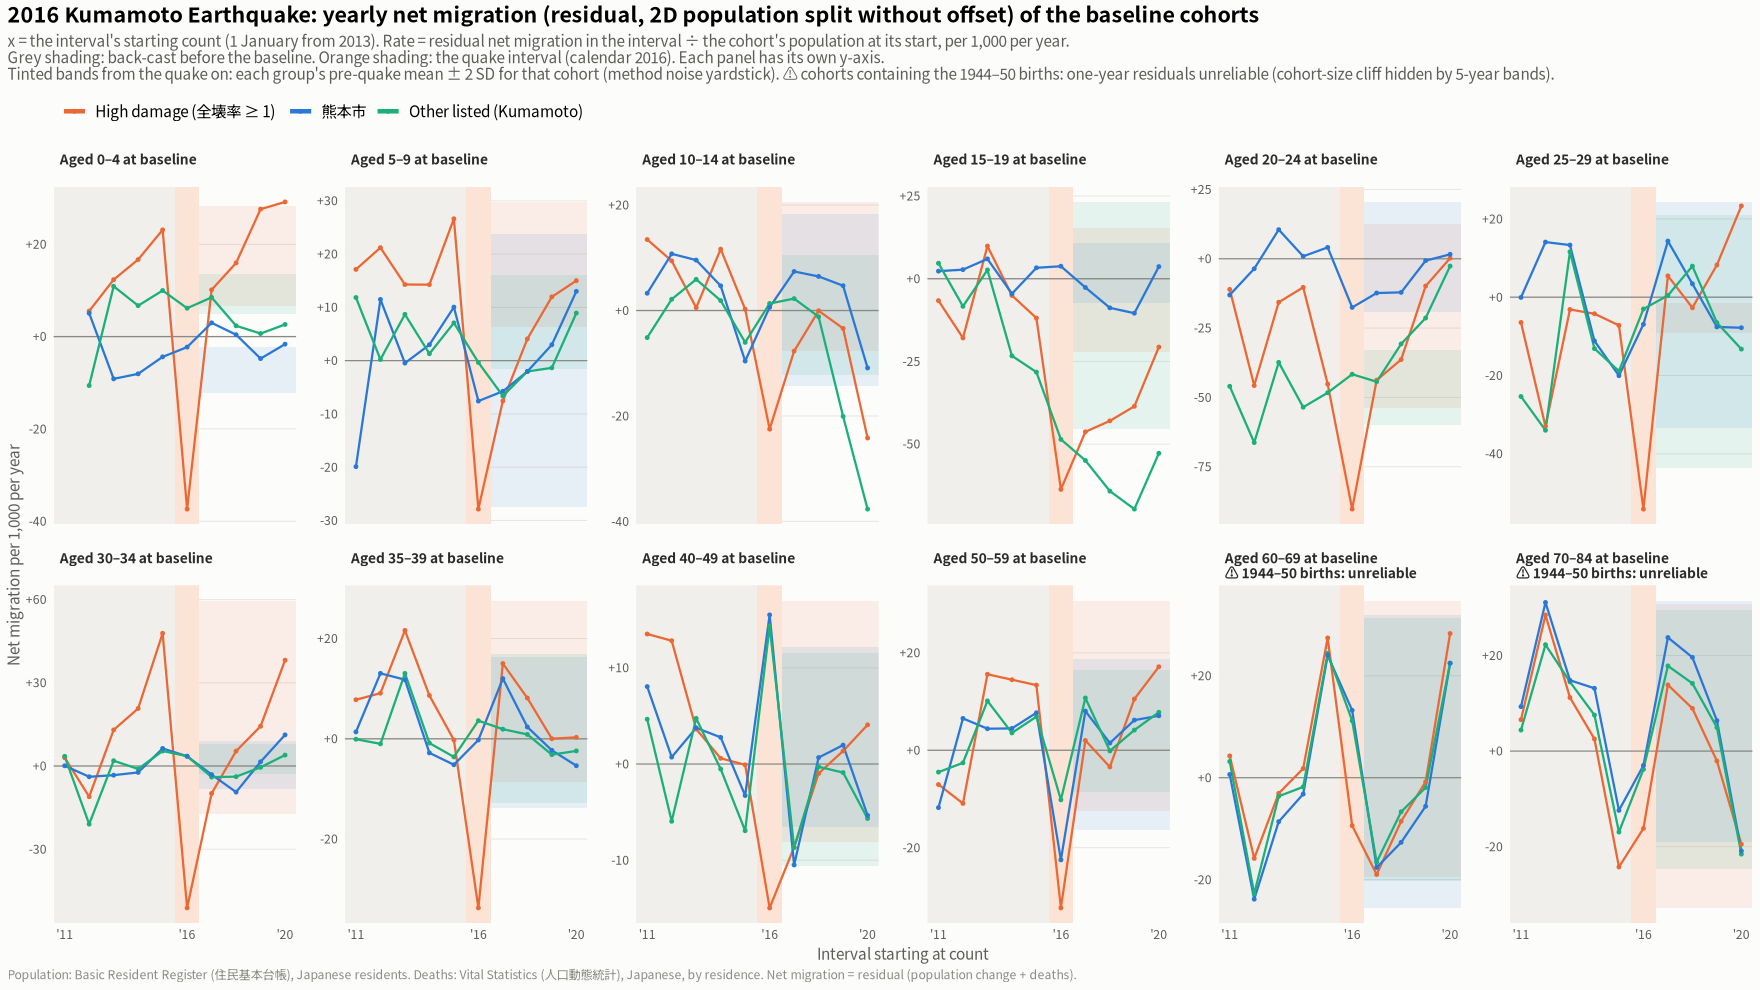

In [16]:
show_save(plot_cohorts("kumamoto") + labs(title = "2016 Kumamoto Earthquake: yearly net migration (residual, 2D population split without offset) of the baseline cohorts"),
          "07_kumamoto_cohort_rates_2d_no_offset", width = 18, height = 9)

## Result: the offset matters at ages 55–79, not for the young

- **Ages 0–39: little change.** The noise SD at ages 20–39 is 4–11 per 1,000 with or without the offset (table under figure 2). The quake signals are the same as in 4r/5r: Kumamoto high damage, 2016, ages 20–24 about −90 per 1,000; Fukushima evacuation areas, after years 1–2, −60 to −80 at ages 0–34.
- **Ages 55–79: the noise roughly doubles to triples.** Median SD at these ages:
  - 岩手・宮城 全壊率 ≥ 1: 7.5 → 21;
  - 熊本市: 6.3 → 21.5.

  Without the offset, the hidden cliff between the 1945–46 and 1947–49 births appears as a single-age wave of ±60–90 per 1,000 that moves one year of age per interval (figure 1). It is as large with 2D as with 1D. Smoothing over time cannot recover a cliff that no year's 5-year bands show.
- **Validation (Kumamoto 2014–2020):**
  - Correlation over all municipality × cohort × year cells: 1D 0.72 → 0.70 and 2D 0.73 → 0.73 when the offset is removed.
  - The losses are concentrated in cohorts aged 60–84 at baseline, where the SD of the gap rises from about 10 to 16–20 per 1,000.
  - Whole-municipality totals don't depend on the split (correlation about 0.97 for all four).
- **Cost:** BIC chooses much smaller λ for age without the offset (median 1,040 vs 23,600), and the 2D fits take about 97 minutes on 16 cores, against about 7 minutes with the offset.

**Bottom line:** results for the target ages (0–14, 20–39) do not depend on the national offset. For older ages the offset is what makes one-year residuals usable. Without it, ages 55–79 should not be read in any of the figures here.